In [2]:
!pip install vit_keras

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 3.0 MB/s eta 0:00:00


In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import confusion_matrix, classification_report
from vit_keras import vit

In [4]:


# Set dataset path
base_dir = '/kaggle/input/flood-dataset/data'

# Image preprocessing
IMG_SIZE = 224
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(rescale=1./255)
val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    os.path.join(base_dir, 'train'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_gen = val_test_datagen.flow_from_directory(
    os.path.join(base_dir, 'valid'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

test_gen = val_test_datagen.flow_from_directory(
    os.path.join(base_dir, 'test'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)


Found 321 images belonging to 2 classes.
Found 81 images belonging to 2 classes.
Found 71 images belonging to 2 classes.


In [5]:

# Load pre-trained Vision Transformer (ViT-B/32)
base_model = vit.vit_b32(
    image_size=IMG_SIZE,
    pretrained=True,
    include_top=False,
    pretrained_top=False
)

# Freeze the base model layers
base_model.trainable = False

# Add custom classification layers
inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs)
x = Dense(1024, activation='relu')(x)
x = Dense(1024, activation='relu')(x)
predictions = Dense(2, activation='softmax')(x)  # Assuming 2 classes: Flood, Non-Flood

# Create the new model
model = Model(inputs=inputs, outputs=predictions)

# Compile the model
model.compile(optimizer=Adam(learning_rate=1e-4),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Train the model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10  # Consistent with original notebook
)

I0000 00:00:1756277742.536719      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1756277742.537502      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


353253686/353253686 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


/usr/local/lib/python3.11/dist-packages/vit_keras/utils.py:85: UserWarning: Resizing position embeddings from 12, 12 to 7, 7
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10


I0000 00:00:1756277772.453934     130 service.cc:148] XLA service 0x7a4834001fa0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1756277772.454892     130 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1756277772.454912     130 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1756277775.061755     130 cuda_dnn.cc:529] Loaded cuDNN version 90300


 1/11 ━━━━━━━━━━━━━━━━━━━━ 6:34 39s/step - accuracy: 0.4062 - loss: 0.8782

I0000 00:00:1756277792.831229     130 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
/usr/local/lib/python3.11/dist-packages/PIL/Image.py:1043: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


11/11 ━━━━━━━━━━━━━━━━━━━━ 66s 3s/step - accuracy: 0.6829 - loss: 0.6049 - val_accuracy: 0.9753 - val_loss: 0.1716
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 262ms/step - accuracy: 0.9714 - loss: 0.1130 - val_accuracy: 0.9753 - val_loss: 0.1021
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 257ms/step - accuracy: 0.9792 - loss: 0.0689 - val_accuracy: 0.9753 - val_loss: 0.0826
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 266ms/step - accuracy: 0.9945 - loss: 0.0303 - val_accuracy: 0.9753 - val_loss: 0.0709
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 247ms/step - accuracy: 1.0000 - loss: 0.0232 - val_accuracy: 0.9753 - val_loss: 0.0597
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 260ms/step - accuracy: 0.9981 - loss: 0.0225 - val_accuracy: 0.9753 - val_loss: 0.0536
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 269ms/step - accuracy: 0.9957 - loss: 0.0221 - val_accuracy: 0.9877 - val_loss: 0.0559
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 266ms/step - accuracy: 0.9966 - loss: 0.0141 - val_accuracy: 0.9753 - val_lo

In [6]:


# Evaluate the model
loss, accuracy = model.evaluate(test_gen)
print(f"Test Accuracy: {accuracy:.2f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step - accuracy: 0.9632 - loss: 0.0608  
Test Accuracy: 0.96


In [ ]:

# Save the model
model.save('/content/drive/MyDrive/pre_trained_vit_b16_model.keras')
print("Model saved successfully to Google Drive.")

Model saved successfully to Google Drive.


3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step  


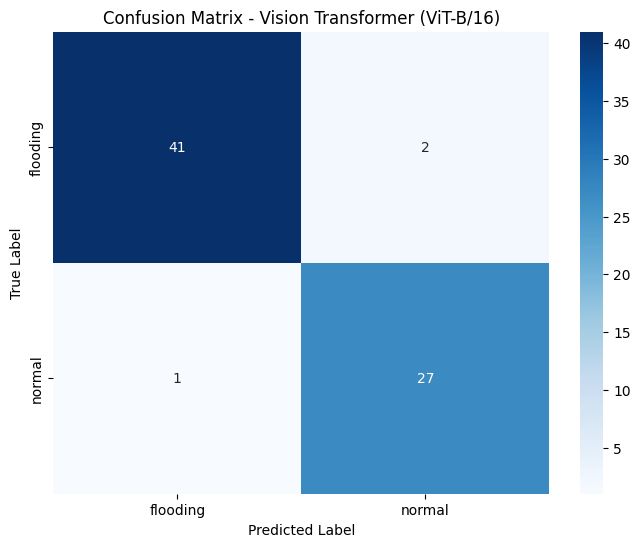

In [7]:

# Generate and plot confusion matrix
predictions = model.predict(test_gen)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_gen.classes
class_labels = list(test_gen.class_indices.keys())

cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Vision Transformer (ViT-B/16)')
plt.show()



In [8]:
# Print classification report
print("\nClassification Report:")
print(classification_report(true_classes, predicted_classes, target_names=class_labels))


Classification Report:
              precision    recall  f1-score   support

    flooding       0.98      0.95      0.96        43
      normal       0.93      0.96      0.95        28

    accuracy                           0.96        71
   macro avg       0.95      0.96      0.96        71
weighted avg       0.96      0.96      0.96        71

